# Stage 2: Predicting unhappy customers

**Business question:** can we tell, at the moment an order is delivered, whether the customer is likely to leave a 1 or 2 star review? If so, customer service can contact them before the review is written.

Input: `data/processed/orders_reviews.csv` (built in Stage 1 with SQL).
Output: test-set predictions, feature importances and model scores saved in `data/processed/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score,
                             classification_report, f1_score, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

DATA = Path("..") / "data" / "processed"
RANDOM_STATE = 42

## 1. Explore

In [2]:
df = pd.read_csv(DATA / "orders_reviews.csv")
print(df.shape)
df.head()

(95824, 14)


,order_id,customer_state,purchase_month,purchase_weekday,n_items,n_sellers,total_price,total_freight,delivery_days,promised_days,days_late,is_late,review_score,unhappy
0,e481f51cbdc54678b7cc49136f2d6af7,SP,2017-10,1,1,1,29.99,8.72,8.4,15.5,-8,0,4,0
1,53cdb2fc8bc7dce0b6741e2150273451,BA,2018-07,2,1,1,118.70,22.76,13.8,19.1,-6,0,4,0
2,47770eb9100c2d0c44946d9cf07ec65d,GO,2018-08,3,1,1,159.90,19.22,9.4,26.6,-18,0,5,0
3,949d5b44dbf5de918fe9c16f97b45f8a,RN,2017-11,6,1,1,45.00,27.20,13.2,26.2,-13,0,5,0
4,ad21c59c0840e6cb83a9ceb5573f8159,SP,2018-02,2,1,1,19.90,8.72,2.9,12.1,-10,0,5,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 95824 entries, 0 to 95823
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          95824 non-null  str    
 1   customer_state    95824 non-null  str    
 2   purchase_month    95824 non-null  str    
 3   purchase_weekday  95824 non-null  int64  
 4   n_items           95824 non-null  int64  
 5   n_sellers         95824 non-null  int64  
 6   total_price       95824 non-null  float64
 7   total_freight     95824 non-null  float64
 8   delivery_days     95824 non-null  float64
 9   promised_days     95824 non-null  float64
 10  days_late         95824 non-null  int64  
 11  is_late           95824 non-null  int64  
 12  review_score      95824 non-null  int64  
 13  unhappy           95824 non-null  int64  
dtypes: float64(4), int64(7), str(3)
memory usage: 14.0 MB


In [4]:
print("Missing values per column:")
print(df.isna().sum())
print("\nDuplicate orders:", df["order_id"].duplicated().sum())

Missing values per column:
order_id            0
customer_state      0
purchase_month      0
purchase_weekday    0
n_items             0
n_sellers           0
total_price         0
total_freight       0
delivery_days       0
promised_days       0
days_late           0
is_late             0
review_score        0
unhappy             0
dtype: int64

Duplicate orders: 0


In [5]:
# Class balance: how many customers are unhappy?
print(df["unhappy"].value_counts())  
print(f"\nShare unhappy: {df['unhappy'].mean():.1%}")

unhappy
0    83552
1    12272
Name: count, dtype: int64

Share unhappy: 12.8%


Only about 13% of orders are unhappy, so the classes are **imbalanced**. A model that always predicts "happy" would be 87% accurate and completely useless, so accuracy is the wrong measure here. We focus on **recall** (how many unhappy customers we catch), **precision** (how many of our alerts are real), and **ROC-AUC** (how well the model ranks risky orders above safe ones).

In [6]:
df[["delivery_days", "promised_days", "days_late", "total_price", "total_freight"]].describe().round(1) 

,delivery_days,promised_days,days_late,total_price,total_freight
count,95824.0,95824.0,95824.0,95824.0,95824.0
mean,12.5,23.7,-11.9,136.8,22.8
std,9.5,8.8,10.1,207.8,21.5
min,0.5,2.0,-147.0,0.8,0.0
25%,6.8,18.3,-17.0,45.9,13.8
50%,10.2,23.2,-12.0,86.2,17.2
75%,15.7,28.4,-7.0,149.9,24.0
max,208.4,155.1,188.0,13440.0,1795.0


## 2. Clean and create features

Stage 1 already removed undelivered orders, kept one review per order, and checked for missing dates, so there is little left to clean. We add one extra feature: **freight share**, the shipping cost as a fraction of the item price (R$20 shipping feels worse on a R$30 item than on a R$500 one).

In [4]:
df["freight_share"] = df["total_freight"] / df["total_price"]

numeric_features = ["n_items", "n_sellers", "total_price", "total_freight", "freight_share",
                    "delivery_days", "promised_days", "days_late", "is_late"]
categorical_features = ["customer_state", "purchase_weekday"]

X = df[numeric_features + categorical_features]
y = df["unhappy"]

**Left out on purpose:**
- `review_score`: this *is* the answer (unhappy means score 1 or 2). Including it would be data leakage.
- `order_id`: just an identifier, with no predictive meaning.
- `purchase_month`: the model would learn which past months were bad, which does not help predict future months.

## 3. Train/test split

We split **before** any scaling or encoding. The scaler then learns its averages from the training data only, so no information from the test set leaks into training. `stratify=y` keeps the 13% unhappy share the same in both sets.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f"Train: {len(X_train):,} rows ({y_train.mean():.1%} unhappy)")
print(f"Test:  {len(X_test):,} rows ({y_test.mean():.1%} unhappy)")

Train: 76,659 rows (12.8% unhappy)
Test:  19,165 rows (12.8% unhappy)


## 4. Preprocessing

A `ColumnTransformer` treats each kind of column differently:
- numbers are put on the same scale with `StandardScaler` (needed for logistic regression)
- categories (state, weekday) become 0/1 columns with `OneHotEncoder`

Putting it inside a `Pipeline` means it is re-fitted on the training part of every cross-validation fold, so there is no leakage there either.

In [7]:
preprocess = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])

## 5. Models and cross-validation

- **Logistic regression**: simple and easy to explain; the baseline.
- **Random forest**: many decision trees voting together; can capture non-linear effects (for example, 1 day late is fine but 7 days late is not).

`class_weight="balanced"` tells both models to pay more attention to the rare unhappy class. We compare them with 5-fold cross-validation **on the training set only**. The test set stays untouched until the end.

In [8]:
models = {
    "Logistic regression": LogisticRegression(class_weight="balanced", max_iter=1000),
    "Random forest": RandomForestClassifier(
        n_estimators=200, min_samples_leaf=20, class_weight="balanced",
        n_jobs=-1, random_state=RANDOM_STATE
    ),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["roc_auc", "recall", "precision", "f1"]

cv_results = {}
for name, model in models.items():
    pipe = Pipeline([("preprocess", preprocess), ("model", model)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    cv_results[name] = {metric: scores[f"test_{metric}"].mean() for metric in scoring}

pd.DataFrame(cv_results).T.round(3)

,roc_auc,recall,precision,f1
Logistic regression,0.747,0.514,0.395,0.447
Random forest,0.748,0.530,0.387,0.447


## 6. Final evaluation on the test set

In [9]:
fitted = {}
probs = {}
rows = []
for name, model in models.items():
    pipe = Pipeline([("preprocess", preprocess), ("model", model)]).fit(X_train, y_train)
    fitted[name] = pipe
    probs[name] = pipe.predict_proba(X_test)[:, 1]
    pred = pipe.predict(X_test)
    rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred),
        "recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred),
        "roc_auc": roc_auc_score(y_test, probs[name]),
    })

metrics = pd.DataFrame(rows).set_index("model").round(3)
metrics

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Logistic regression,0.833,0.385,0.513,0.440,0.743
Random forest,0.828,0.379,0.537,0.444,0.746


In [12]:
best = fitted["Random forest"]
print(classification_report(y_test, best.predict(X_test), target_names=["happy", "unhappy"]))

              precision    recall  f1-score   support

       happy       0.93      0.87      0.90     16711
     unhappy       0.38      0.54      0.44      2454

    accuracy                           0.83     19165
   macro avg       0.65      0.70      0.67     19165
weighted avg       0.86      0.83      0.84     19165



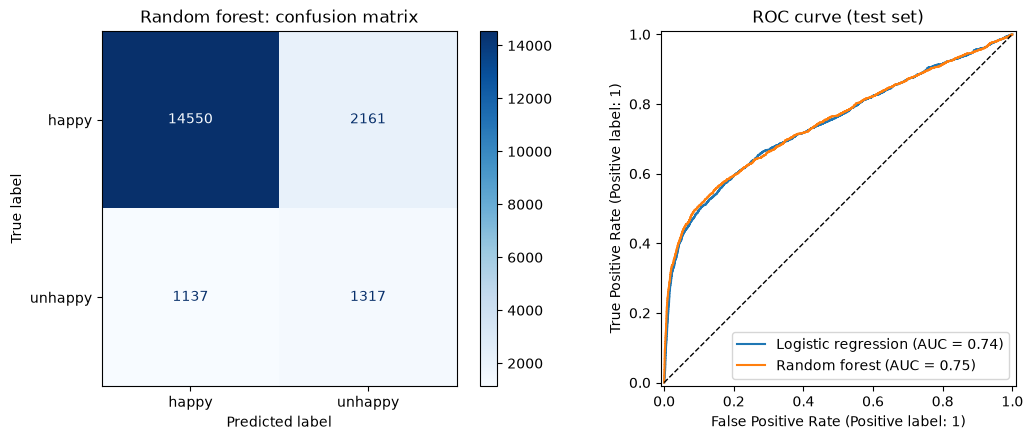

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

ConfusionMatrixDisplay.from_estimator(
    best, X_test, y_test, display_labels=["happy", "unhappy"], cmap="Blues", ax=axes[0]
)
axes[0].set_title("Random forest: confusion matrix")

for name, p in probs.items():
    RocCurveDisplay.from_predictions(y_test, p, name=name, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", linewidth=1)
axes[1].set_title("ROC curve (test set)")

plt.tight_layout()
plt.show()

**Why accuracy alone is misleading:** a model that always says "happy" scores about 87% accuracy but catches zero unhappy customers. For this business problem, missing an unhappy customer is the costly mistake, so **recall** matters most, balanced against precision so that customer service is not flooded with false alarms.

## 7. Which features matter?

We use **permutation importance**: shuffle one column at a time on the test set and measure how much the ROC-AUC drops. A big drop means the model relies on that feature. This works on the original columns, so `customer_state` counts as one feature rather than 27 separate 0/1 columns.

In [16]:
perm = permutation_importance(
    best, X_test, y_test, scoring="roc_auc", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1
)
importance = (
    pd.DataFrame({"feature": X_test.columns,
                  "importance": perm.importances_mean,
                  "std": perm.importances_std})
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)
importance.round(4)

,feature,importance,std
0,n_items,0.0347,0.0015
1,delivery_days,0.0218,0.0010
2,days_late,0.0179,0.0017
3,is_late,0.0039,0.0011
4,total_freight,0.0024,0.0007
5,n_sellers,0.0024,0.0007
6,promised_days,0.0014,0.0010
7,freight_share,0.0009,0.0010
8,customer_state,0.0005,0.0012
9,total_price,0.0004,0.0003


## 8. Save the results

In [17]:
predictions = pd.DataFrame({
    "order_id": df.loc[X_test.index, "order_id"],
    "actual": y_test,
    "prob_logreg": probs["Logistic regression"].round(4),
    "prob_rf": probs["Random forest"].round(4),
    "pred_rf": best.predict(X_test),
})
predictions.to_csv(DATA / "test_predictions.csv", index=False)
importance.to_csv(DATA / "feature_importance.csv", index=False)
metrics.to_csv(DATA / "model_metrics.csv")
print("Saved test_predictions.csv, feature_importance.csv and model_metrics.csv")

Saved test_predictions.csv, feature_importance.csv and model_metrics.csv


## 9. Conclusions

- **Both models perform about the same** (test ROC-AUC 0.74 to 0.75). The random forest catches slightly more unhappy customers (recall 0.54 against 0.51), but the simpler logistic regression is almost as good and much easier to explain.
- **The model catches about half of unhappy customers** at a precision of about 0.38. Roughly 2 in 5 alerts are real, which is about three times better than contacting customers at random (12.8%).
- **The biggest drivers are the number of items, delivery time and lateness.** Orders with several items often arrive in separate deliveries from different sellers, which adds more chances for something to go wrong.
- **State and weekday add almost nothing** once delivery timing is known. Weekday's importance is slightly negative, meaning it is just noise.
- **Limitations:** the model only sees order and delivery data. Product quality, which is probably the other big reason for bad reviews, is not in these features. The review text could be explored with NLP as a next step.